# Structures, thermal and separation evidence

The integrated trajectory provides **time-correlated** load cases. Keep each case's force, moment, mass and acceleration together when constructing finite element loads. Do not combine independent peak values as though they occurred at the same instant.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from hyperion.workspace import current_flight
from hyperion.verification import ROOT, activities, input_contracts

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_colwidth', 100)

In [2]:
context = current_flight()
flight, summary, model = context
display(model.load_cases[['case','t_s','mass_kg','normal_force_N','aero_moment_Nm',
                         'payload_axial_force_N','payload_lateral_force_N']].round(2))

,case,t_s,mass_kg,normal_force_N,aero_moment_Nm,payload_axial_force_N,payload_lateral_force_N
0,Max-Q,63.40,409096.85,4398.16,154552.78,57030.29,164.86
1,Max-Qalpha,46.60,437794.11,25361.58,892656.53,60892.48,456.07
2,Max axial acceleration,217.76,121234.61,411.12,6382.99,240597.63,24.97
3,Max lateral acceleration,220.96,79947.16,525.02,2512.08,47946.66,756.54
4,Max aerodynamic moment,46.60,437794.11,25361.58,892656.53,60892.48,456.07
5,Max TVC demand,46.60,437794.11,25361.58,892656.53,60892.48,456.07
6,Max thrust,0.00,528757.07,144.26,5054.53,55178.85,12.62
7,Max aerodynamic normal force,46.60,437794.11,25361.58,892656.53,60892.48,456.07
8,Max aerodynamic axial force,76.40,388581.98,2050.98,70742.61,58256.42,64.26


## Recompute the source pressure-sizing trade

The source tank sheet contains a 1–6 mm thickness sweep at 87.022608 psi and radius 2.7 m. Several spreadsheet stress ratios have invalid references. The following calculation uses the source Al2219 yield value of 43 ksi and requirement yield factor **1.25**. It is a pressure-only cylindrical membrane trade, **not installed-tank verification**: weld efficiency, penetrations, thermal stresses, combined flight loads, buckling and final thickness remain to be established.

Sources: `Structures Sizing.xlsx`, `Tank Sizing!B3:D8` and `Material Properties!B3:H3`; `STR.3.SYS.03`. Ultimate checks must use the separate required factor **1.40**, not the sheet's 1.25 assumption.

,Thickness (mm),Yield utilization
0,1,5.915
1,2,2.958
2,3,1.972
3,4,1.479
4,5,1.183
5,6,0.986


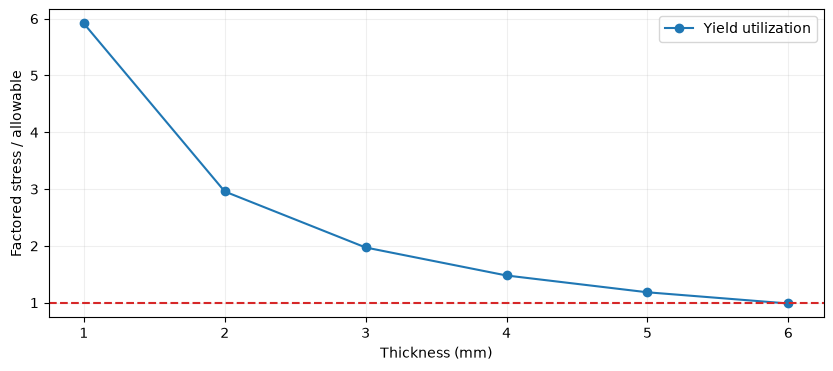

In [3]:
from hyperion.structures import tank_stress
PRESSURE_PA = 87.0226084737 * 6894.757293168
RADIUS_M = 2.7
YIELD_PA = 43_000 * 6894.757293168
rows = []
for thickness_mm in [1,2,3,4,5,6]:
    check = tank_stress(radius_m=RADIUS_M, thickness_m=thickness_mm/1000,
        pressure_pa=PRESSURE_PA, axial_force_n=0, bending_moment_nm=0, torque_nm=0,
        yield_allowable_pa=YIELD_PA, joint_efficiency=1, load_factor=1.25)
    rows.append({'Thickness (mm)': thickness_mm, 'Yield utilization': check['yield']['utilization']})
trade = pd.DataFrame(rows)
display(trade.round(3))
trade.plot(x='Thickness (mm)', y='Yield utilization', marker='o')
plt.axhline(1,color='tab:red',ls='--'); plt.ylabel('Factored stress / allowable'); plt.show()

## Models ready for supplied design data

Shared functions solve assembled static/modal/transient finite element matrices, combined section/tank stresses, buckling, joints, spectral vibration and shock, fatigue, fracture, thermal networks, venting and clearance. Model matrices must come from a documented geometry, mesh, material and boundary-condition definition. No synthetic stiffness matrix is treated as the vehicle.

Relative-stage and spacecraft propagation in `hyperion.mission` uses supplied release positions, velocities, dimensions and dispersions. The ascent's single continuing-body impulse does not demonstrate no recontact.

In [4]:
from hyperion import structures
contracts = input_contracts()
display(contracts[contracts.calculation.isin(structures.FUNCTIONS)])

,calculation,required_inputs,description
31,section_stress,"axial_force_n, bending_y_nm, bending_z_nm, shear_y_n, shear_z_n, torque_nm, area_m2, iy_m4, iz_m...",Prismatic section about principal centroidal axes; Saint-Venant circular torsion.
32,tank_stress,"radius_m, thickness_m, pressure_pa, axial_force_n, bending_moment_nm, torque_nm, yield_allowable...",Thin closed-end cylinder membrane plus axial bending; extrema at both fibers.
33,buckling,"youngs_modulus_pa, poisson_ratio, radius_m, thickness_m, length_m, area_m2, min_second_moment_m4...",Independent ideal axial shell and Euler-column screens with supplied KDFs.
34,buckling_eigenvalue,"stiffness_n_m, destabilizing_geometric_stiffness_n_m, load_factor",K v = lambda G v; G is supplied for one reference destabilizing load case.
35,joint_strength,"fastener_tension_n, fastener_shear_n, fastener_tensile_area_m2, fastener_shear_area_m2, bearing_...",Per-fastener loads from an external load distribution; equal load not assumed.
36,fe_static,"stiffness_n_m, force_n, constrained_dofs",Supplied assembled linear FE matrix; fixed constraints are exact elimination.
37,modal,"stiffness_n_m, mass_kg",Boundary-condition-reduced matrices; mass-normalized real modes.
38,fe_transient,"times_s, stiffness_n_m, mass_kg, damping_ns_m, force_n, initial_displacement_m, initial_velocity...",M u''+C u'+K u=f-M gamma a_base; u is relative to prescribed base.
39,base_psd_response,"frequency_hz, base_acceleration_psd_m2_s4_hz, stiffness_n_m, mass_kg, damping_ns_m, base_influence","One-sided base-acceleration PSD through linear multi-DOF FRF, trapezoid in Hz."
40,shock_response_spectrum,"times_s, acceleration_m_s2, natural_frequencies_hz, damping_ratio",Absolute-acceleration SRS of zero-initial-state SDOF oscillators.
